# Solving the Traveling Salesman  Problem using Local Search

Points: 10

## The [Traveling Salesman Problem](https://en.wikipedia.org/wiki/Travelling_salesman_problem)

* __Goal:__ Find the shortest tour visiting each of $n$ cities exactly once and returning back to the starting city. Given are pairwise distances between cities, where $d_{i,j}$ is the distance from city $i$ to city $j$. 

* __State space:__ Each state represents a tour. The cities are numbered and a tour can be expressed as vector  $\pi$ with the order in which the cities are visited (a [permutation](https://en.wikipedia.org/wiki/Permutation)). That is, $\pi(1)$ is the index of the first city to visit, $\pi(2)$ the index of the second, and so on.

* __Objective function:__ Minimize the tour length. The optimization problem is to find the optimal tour $\pi^*$ through the $n$ cities and returning to the starting city:

  > minimize: $\mathrm{tourlength}(\pi) = d_{\pi(n),\pi(1)} + \sum_{i = 1}^{n-1} d_{\pi(i),\pi(i+1)}$
  > 
  > subject to: $\pi \ \text{is a valid permutation vector}$

* __Local moves:__ Exchange two cities in the order.

## Helper functions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import random

np.set_printoptions(precision=2)
pd.set_option('display.precision', 2)

# make the results repeatable
np.random.seed(1234)
# make the results of the random module repeatable as well (random_tour uses it)
random.seed(1234)

In [2]:
def random_tour(n):
    """Create a random tour"""
    
    tour = list(range(n))
    random.shuffle(tour)
    return(tour)

random_tour(10)

[2, 8, 3, 5, 6, 4, 9, 0, 1, 7]

In [3]:
from scipy.spatial.distance import pdist
from scipy.spatial.distance import squareform

def random_tsp(n):
    """
    Create a random (Euclidean) traveling salesman problem. Choose n points randomly in a 1 x 1 unit square and calulates a 
    pairwise Euclidean distance matrix.
    """
    
    pos = pd.DataFrame({
        "x" : np.random.uniform(size = n),
        "y" : np.random.uniform(size = n)
    })
    
    dist = squareform(pdist(pos))
    
    return({"pos": pos, "dist": dist})
    
tsp = random_tsp(10)

print(f"Positions:\n{tsp['pos']}")
print(f"Distance matrix:\n{pd.DataFrame(tsp['dist'])})")

Positions:
      x     y
0  0.19  0.36
1  0.62  0.50
2  0.44  0.68
3  0.79  0.71
4  0.78  0.37
5  0.27  0.56
6  0.28  0.50
7  0.80  0.01
8  0.96  0.77
9  0.88  0.88
Distance matrix:
      0     1     2     3     4     5     6     7     8     9
0  0.00  0.45  0.41  0.69  0.59  0.22  0.17  0.70  0.87  0.86
1  0.45  0.00  0.26  0.27  0.20  0.35  0.35  0.52  0.43  0.46
2  0.41  0.26  0.00  0.35  0.46  0.21  0.24  0.76  0.53  0.48
3  0.69  0.27  0.35  0.00  0.34  0.53  0.55  0.70  0.18  0.19
4  0.59  0.20  0.46  0.34  0.00  0.54  0.52  0.36  0.44  0.52
5  0.22  0.35  0.21  0.53  0.54  0.00  0.06  0.76  0.72  0.68
6  0.17  0.35  0.24  0.55  0.52  0.06  0.00  0.72  0.73  0.71
7  0.70  0.52  0.76  0.70  0.36  0.76  0.72  0.00  0.77  0.87
8  0.87  0.43  0.53  0.18  0.44  0.72  0.73  0.77  0.00  0.14
9  0.86  0.46  0.48  0.19  0.52  0.68  0.71  0.87  0.14  0.00)


In [4]:
def tour_length(tsp, tour):
    """Caclulate the length of a tour, i.e., the objective function."""
    
    # make sure tour is a Python list (not an array or a numpy.array)
    if not isinstance(tour, list): tour = tour.tolist()
    
    tl = 0
    dist = tsp["dist"]
    
    for i in range(len(tour)-1):
        tl += dist[tour[i], tour[i+1]]
    
    tl += dist[tour[-1], tour[0]]
    
    return(tl)
        
tour = random_tour(10)
tour_length(tsp, tour)

np.float64(5.873881857725191)

Tour length: 5.87


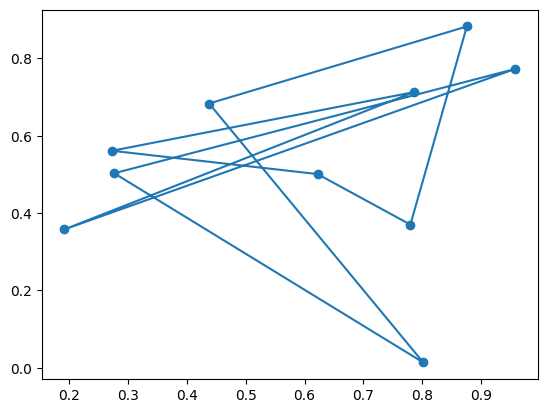

In [5]:
def show_tsp(tsp, tour = None):  
    """display the traveling salesman problem and a tour."""
    
    pos = tsp["pos"]
    
    plt.scatter(pos["x"], pos["y"])
    
    if tour is not None:
        # make sure tour is a Python list (not an array or a numpy.array)
        if not isinstance(tour, list): tour = tour.tolist()
        
        print(f"Tour length: {round(tour_length(tsp, tour), 2)}")
        
        pos_ = pos.reindex(tour)
        pos_ = pd.concat([pos_, pos_.head(1)])
        plt.plot(pos_["x"], pos_["y"])
    
    plt.show()
    
show_tsp(tsp, tour)

## Mô hình hóa bài toán & toán tử lân cận dùng chung (Bài 7)

* **Trạng thái:** một hoán vị `tour` của $n$ thành phố (tour là chu trình khép kín, thành phố cuối nối lại thành phố đầu).
* **Hàm mục tiêu:** `tour_length(tsp, tour)` – tổng độ dài chu trình khép kín; mục tiêu là **cực tiểu hóa** (giảm độ dài = "cải thiện").
* **Toán tử lân cận (được chọn):** **hoán đổi vị trí của hai thành phố** `i < j` trong tour (`tour[i], tour[j] = tour[j], tour[i]`). Mọi hoán vị sinh ra đều hợp lệ nên ràng buộc "mỗi thành phố đúng một lần" luôn được giữ.
* **Kích thước lân cận:** $\binom{n}{2} = n(n-1)/2$ trạng thái láng giềng cho mỗi tour.
* **Quy ước:** toàn bộ thuật toán bên dưới (Steepest-ascent, Random Restarts, Stochastic, First-choice, Simulated Annealing, và cả Genetic Algorithm ở phần bonus khi đột biến) đều dùng **cùng toán tử hoán đổi hai thành phố** để so sánh công bằng. Chỉ so sánh một biến số là thuật toán.
* **Quy ước đo:** `iterations` = số vòng lặp chính của thuật toán; `evaluations` = số lần gọi `tour_length()`; `time_ms` = thời gian chạy (mili giây); `history` = giá trị độ dài tour theo vòng lặp (dùng để vẽ đường hội tụ).

Bên dưới tạo một bài toán TSP dùng chung (20 thành phố) và **một tour khởi đầu chung** để minh họa từng thuật toán.

Số thành phố: 20
Số láng giềng của mỗi tour (hoán đổi 2 thành phố): 190
Tour khởi đầu: [0, 2, 16, 1, 10, 19, 17, 18, 7, 3, 8, 4, 14, 11, 12, 13, 6, 9, 5, 15]
Tour length: 10.18


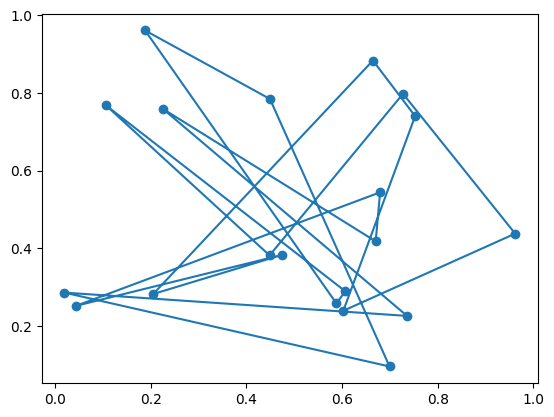

In [6]:
# Bài toán TSP dùng chung để minh họa cho tất cả các thuật toán bên dưới
np.random.seed(2024)
random.seed(2024)

n_demo = 20
tsp_demo = random_tsp(n_demo)
start_tour = random_tour(n_demo)

print(f"Số thành phố: {n_demo}")
print(f"Số láng giềng của mỗi tour (hoán đổi 2 thành phố): {n_demo * (n_demo - 1) // 2}")
print(f"Tour khởi đầu: {start_tour}")
show_tsp(tsp_demo, start_tour)

## Steepest-ascend Hill Climbing Search [3 Points]

Calculate the objective function for all local moves (move each queen within its column) and always choose the best among all local moves.

=== Steepest-ascent Hill Climbing ===
Độ dài tour ban đầu : 10.1787
Độ dài tour cuối    : 4.1683
Cải thiện tương đối : 59.05 %
Số vòng lặp (bước)  : 12
Số lần gọi tour_length(): 2471
Thời gian chạy      : 9.47 ms
Tour cuối           : [0, 15, 4, 3, 10, 5, 2, 17, 16, 9, 8, 7, 14, 6, 11, 13, 18, 19, 1, 12]
Tour length: 4.17


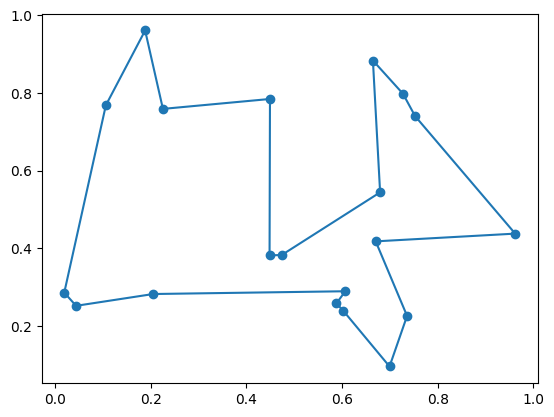

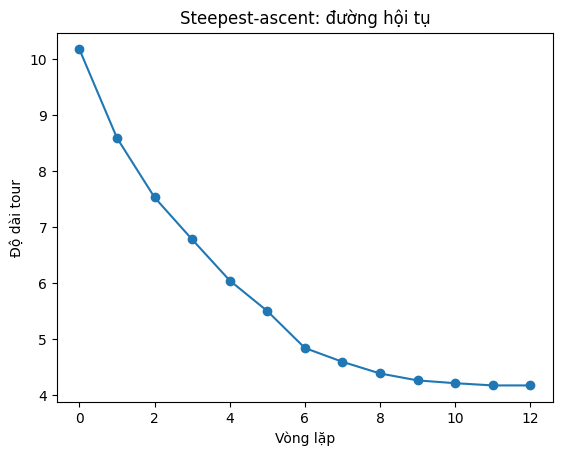

In [7]:
import time

def steepest_ascent(tsp, tour = None, max_iter = 10000):
    """
    Steepest-ascent Hill Climbing cho TSP.
    Mỗi vòng lặp: đánh giá TẤT CẢ láng giềng (hoán đổi mọi cặp thành phố i < j),
    chọn láng giềng có tour ngắn nhất; chỉ di chuyển nếu nó tốt hơn trạng thái hiện tại.
    Dừng khi không còn láng giềng nào cải thiện (cực trị cục bộ).
    """
    t0 = time.time()
    n = len(tsp["dist"])
    current = list(tour) if tour is not None else random_tour(n)
    current_len = tour_length(tsp, current)
    init_len = current_len

    evaluations = 1
    iterations = 0
    history = [current_len]

    while iterations < max_iter:
        best_neighbor = None
        best_len = current_len

        for i in range(n - 1):
            for j in range(i + 1, n):
                neighbor = current.copy()
                neighbor[i], neighbor[j] = neighbor[j], neighbor[i]
                neighbor_len = tour_length(tsp, neighbor)
                evaluations += 1
                if neighbor_len < best_len - 1e-12:
                    best_neighbor, best_len = neighbor, neighbor_len

        if best_neighbor is None:      # không có láng giềng tốt hơn -> local optimum
            break

        current, current_len = best_neighbor, best_len
        iterations += 1
        history.append(current_len)

    return {"tour": current, "length": current_len, "init_length": init_len,
            "iterations": iterations, "evaluations": evaluations,
            "time_ms": (time.time() - t0) * 1e3, "history": history}


# ---- Chạy thử trên bài toán dùng chung ----
res_steepest = steepest_ascent(tsp_demo, start_tour)

print("=== Steepest-ascent Hill Climbing ===")
print(f"Độ dài tour ban đầu : {res_steepest['init_length']:.4f}")
print(f"Độ dài tour cuối    : {res_steepest['length']:.4f}")
print(f"Cải thiện tương đối : {(res_steepest['init_length'] - res_steepest['length']) / res_steepest['init_length'] * 100:.2f} %")
print(f"Số vòng lặp (bước)  : {res_steepest['iterations']}")
print(f"Số lần gọi tour_length(): {res_steepest['evaluations']}")
print(f"Thời gian chạy      : {res_steepest['time_ms']:.2f} ms")
print(f"Tour cuối           : {res_steepest['tour']}")
show_tsp(tsp_demo, res_steepest["tour"])

plt.plot(res_steepest["history"], marker = "o")
plt.xlabel("Vòng lặp")
plt.ylabel("Độ dài tour")
plt.title("Steepest-ascent: đường hội tụ")
plt.show()

## Steepest-ascend Hill Climbing Search with Random Restarts [1 Point]

Steepest-ascend with random restarts.

=== Steepest-ascent Hill Climbing with Random Restarts ===
Số lần khởi động lại : 20
Độ dài tour ban đầu (lần khởi động đầu): 10.1787
Độ dài tour tốt nhất : 3.6155
Cải thiện tương đối  : 64.48 %
Tổng số vòng lặp     : 286
Tổng số lần gọi tour_length(): 58160
Thời gian chạy       : 174.73 ms
Tour tốt nhất        : [12, 1, 19, 15, 18, 7, 13, 11, 6, 14, 16, 17, 2, 5, 10, 3, 4, 9, 8, 0]
Tour length: 3.62


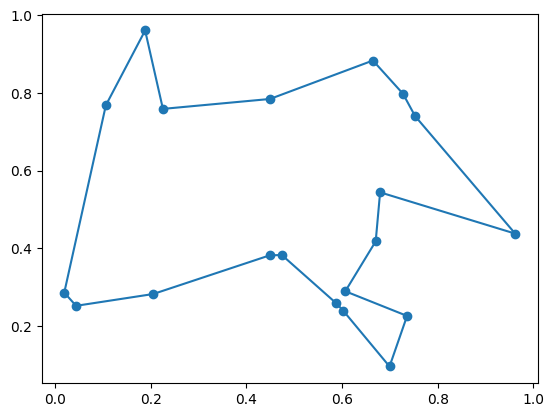

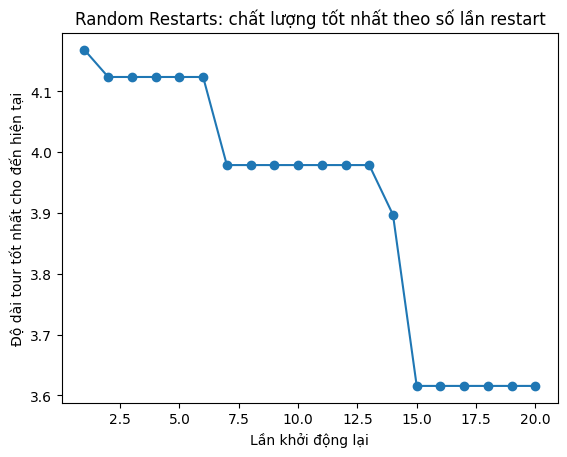

In [8]:
def steepest_ascent_random_restarts(tsp, n_restarts = 20, tour = None):
    """
    Steepest-ascent Hill Climbing với Random Restarts.
    Chạy steepest_ascent() từ n_restarts tour khởi đầu khác nhau (lần đầu dùng `tour` nếu được cung cấp,
    các lần sau dùng tour ngẫu nhiên) và giữ lại tour tốt nhất tìm được.
    """
    t0 = time.time()
    n = len(tsp["dist"])

    best = None
    init_len = None
    iterations = 0
    evaluations = 0
    history = []              # độ dài tốt nhất sau mỗi lần khởi động lại

    for r in range(n_restarts):
        start = list(tour) if (tour is not None and r == 0) else random_tour(n)
        res = steepest_ascent(tsp, start)

        if r == 0:
            init_len = res["init_length"]
        iterations += res["iterations"]
        evaluations += res["evaluations"]

        if best is None or res["length"] < best["length"]:
            best = res
        history.append(best["length"])

    return {"tour": best["tour"], "length": best["length"], "init_length": init_len,
            "iterations": iterations, "evaluations": evaluations, "restarts": n_restarts,
            "time_ms": (time.time() - t0) * 1e3, "history": history}


# ---- Chạy thử trên bài toán dùng chung ----
random.seed(1)
res_rr = steepest_ascent_random_restarts(tsp_demo, n_restarts = 20, tour = start_tour)

print("=== Steepest-ascent Hill Climbing with Random Restarts ===")
print(f"Số lần khởi động lại : {res_rr['restarts']}")
print(f"Độ dài tour ban đầu (lần khởi động đầu): {res_rr['init_length']:.4f}")
print(f"Độ dài tour tốt nhất : {res_rr['length']:.4f}")
print(f"Cải thiện tương đối  : {(res_rr['init_length'] - res_rr['length']) / res_rr['init_length'] * 100:.2f} %")
print(f"Tổng số vòng lặp     : {res_rr['iterations']}")
print(f"Tổng số lần gọi tour_length(): {res_rr['evaluations']}")
print(f"Thời gian chạy       : {res_rr['time_ms']:.2f} ms")
print(f"Tour tốt nhất        : {res_rr['tour']}")
show_tsp(tsp_demo, res_rr["tour"])

plt.plot(range(1, len(res_rr["history"]) + 1), res_rr["history"], marker = "o")
plt.xlabel("Lần khởi động lại")
plt.ylabel("Độ dài tour tốt nhất cho đến hiện tại")
plt.title("Random Restarts: chất lượng tốt nhất theo số lần restart")
plt.show()

## Stochastic Hill Climbing [1 Points]

Chooses randomly from among all uphill moves.

=== Stochastic Hill Climbing (chọn ngẫu nhiên trong mọi nước đi cải thiện) ===
Độ dài tour ban đầu : 10.1787
Độ dài tour cuối    : 4.0719
Cải thiện tương đối : 60.00 %
Số vòng lặp (bước)  : 39
Số lần gọi tour_length(): 7601
Thời gian chạy      : 31.57 ms
Tour cuối           : [5, 2, 17, 9, 8, 18, 15, 0, 12, 1, 19, 13, 7, 11, 6, 14, 16, 4, 3, 10]
Tour length: 4.07


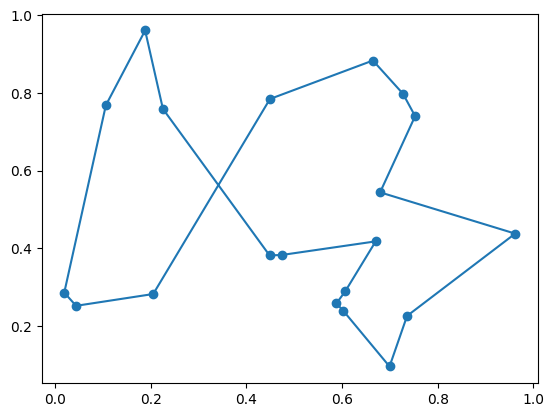

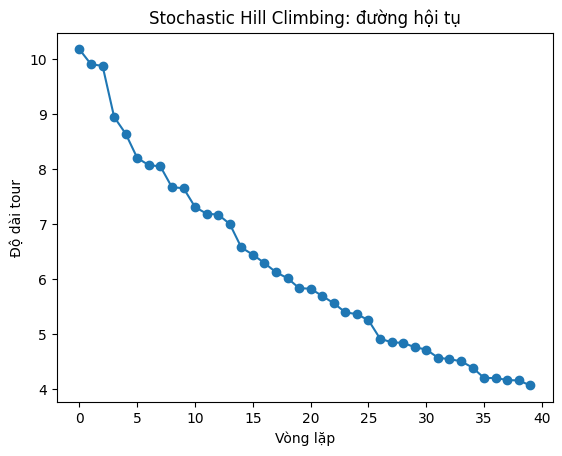

In [9]:
def stochastic_hill_climbing(tsp, tour = None, max_iter = 10000):
    """
    Stochastic Hill Climbing cho TSP.
    Mỗi vòng lặp: liệt kê TẤT CẢ láng giềng (hoán đổi hai thành phố) tốt hơn trạng thái hiện tại,
    rồi chọn NGẪU NHIÊN một trong số đó. Dừng khi không còn nước đi cải thiện.
    """
    t0 = time.time()
    n = len(tsp["dist"])
    current = list(tour) if tour is not None else random_tour(n)
    current_len = tour_length(tsp, current)
    init_len = current_len

    evaluations = 1
    iterations = 0
    history = [current_len]

    while iterations < max_iter:
        better_moves = []         # (i, j, độ dài mới) của mọi nước đi cải thiện

        for i in range(n - 1):
            for j in range(i + 1, n):
                neighbor = current.copy()
                neighbor[i], neighbor[j] = neighbor[j], neighbor[i]
                neighbor_len = tour_length(tsp, neighbor)
                evaluations += 1
                if neighbor_len < current_len - 1e-12:
                    better_moves.append((i, j, neighbor_len))

        if len(better_moves) == 0:     # local optimum
            break

        i, j, current_len = random.choice(better_moves)
        current[i], current[j] = current[j], current[i]
        iterations += 1
        history.append(current_len)

    return {"tour": current, "length": current_len, "init_length": init_len,
            "iterations": iterations, "evaluations": evaluations,
            "time_ms": (time.time() - t0) * 1e3, "history": history}


# ---- Chạy thử trên bài toán dùng chung ----
random.seed(1)
res_stoch = stochastic_hill_climbing(tsp_demo, start_tour)

print("=== Stochastic Hill Climbing (chọn ngẫu nhiên trong mọi nước đi cải thiện) ===")
print(f"Độ dài tour ban đầu : {res_stoch['init_length']:.4f}")
print(f"Độ dài tour cuối    : {res_stoch['length']:.4f}")
print(f"Cải thiện tương đối : {(res_stoch['init_length'] - res_stoch['length']) / res_stoch['init_length'] * 100:.2f} %")
print(f"Số vòng lặp (bước)  : {res_stoch['iterations']}")
print(f"Số lần gọi tour_length(): {res_stoch['evaluations']}")
print(f"Thời gian chạy      : {res_stoch['time_ms']:.2f} ms")
print(f"Tour cuối           : {res_stoch['tour']}")
show_tsp(tsp_demo, res_stoch["tour"])

plt.plot(res_stoch["history"], marker = "o")
plt.xlabel("Vòng lặp")
plt.ylabel("Độ dài tour")
plt.title("Stochastic Hill Climbing: đường hội tụ")
plt.show()

## First-choice Hill Climbing [1 Point]

First-choice hill climbing is a type of stochastic hill climbing that generates one random local neighbor at a time and accept it if it has a better objective function value than the current state.

=== First-choice Hill Climbing ===
Độ dài tour ban đầu : 10.1787
Độ dài tour cuối    : 4.0719
Cải thiện tương đối : 60.00 %
Số vòng lặp (số láng giềng đã thử): 2193
Số nước đi được chấp nhận: 41
Số lần gọi tour_length(): 2194
Thời gian chạy      : 8.46 ms
Tour cuối           : [2, 5, 10, 3, 4, 16, 14, 6, 11, 7, 13, 19, 1, 12, 0, 15, 18, 8, 9, 17]
Tour length: 4.07


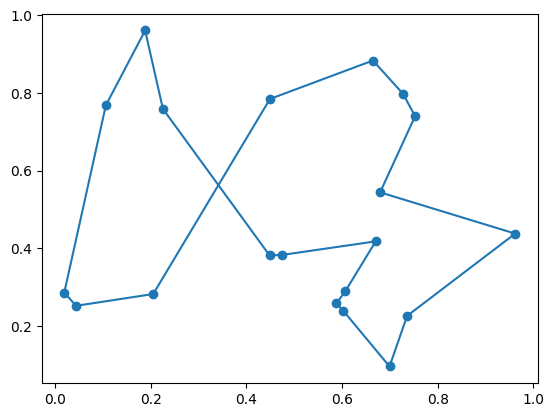

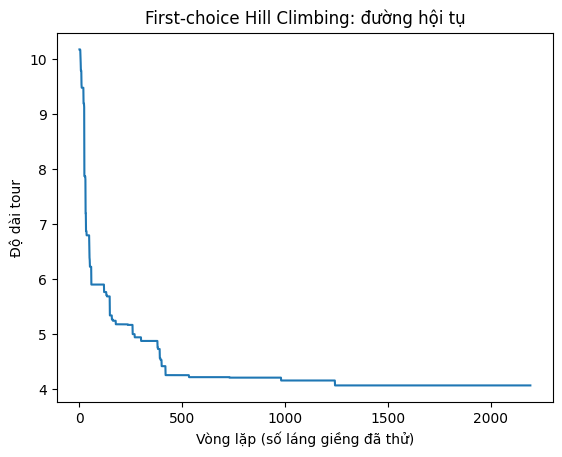

In [10]:
def first_choice_hill_climbing(tsp, tour = None, max_iter = 100000, max_no_improve = None):
    """
    First-choice Hill Climbing cho TSP.
    Mỗi vòng lặp: sinh MỘT láng giềng ngẫu nhiên (hoán đổi hai thành phố ngẫu nhiên) và chấp nhận
    ngay nếu tour ngắn hơn. Để tránh lặp vô hạn, dừng khi:
      - đã thử liên tiếp `max_no_improve` láng giềng mà không cải thiện được
        (mặc định = 5 x kích thước lân cận = 5 * n(n-1)/2), hoặc
      - đạt `max_iter` lần thử.
    """
    t0 = time.time()
    n = len(tsp["dist"])
    current = list(tour) if tour is not None else random_tour(n)
    current_len = tour_length(tsp, current)
    init_len = current_len

    if max_no_improve is None:
        max_no_improve = 5 * (n * (n - 1) // 2)

    evaluations = 1
    iterations = 0            # số láng giềng đã sinh ra (số lần thử)
    moves = 0                 # số nước đi được chấp nhận
    no_improve = 0
    history = [current_len]

    while iterations < max_iter and no_improve < max_no_improve:
        i, j = random.sample(range(n), 2)
        neighbor = current.copy()
        neighbor[i], neighbor[j] = neighbor[j], neighbor[i]
        neighbor_len = tour_length(tsp, neighbor)
        evaluations += 1
        iterations += 1

        if neighbor_len < current_len - 1e-12:
            current, current_len = neighbor, neighbor_len
            moves += 1
            no_improve = 0
        else:
            no_improve += 1

        history.append(current_len)

    return {"tour": current, "length": current_len, "init_length": init_len,
            "iterations": iterations, "evaluations": evaluations, "moves": moves,
            "time_ms": (time.time() - t0) * 1e3, "history": history}


# ---- Chạy thử trên bài toán dùng chung ----
random.seed(1)
res_fc = first_choice_hill_climbing(tsp_demo, start_tour)

print("=== First-choice Hill Climbing ===")
print(f"Độ dài tour ban đầu : {res_fc['init_length']:.4f}")
print(f"Độ dài tour cuối    : {res_fc['length']:.4f}")
print(f"Cải thiện tương đối : {(res_fc['init_length'] - res_fc['length']) / res_fc['init_length'] * 100:.2f} %")
print(f"Số vòng lặp (số láng giềng đã thử): {res_fc['iterations']}")
print(f"Số nước đi được chấp nhận: {res_fc['moves']}")
print(f"Số lần gọi tour_length(): {res_fc['evaluations']}")
print(f"Thời gian chạy      : {res_fc['time_ms']:.2f} ms")
print(f"Tour cuối           : {res_fc['tour']}")
show_tsp(tsp_demo, res_fc["tour"])

plt.plot(res_fc["history"])
plt.xlabel("Vòng lặp (số láng giềng đã thử)")
plt.ylabel("Độ dài tour")
plt.title("First-choice Hill Climbing: đường hội tụ")
plt.show()

## Simulated Annealing [2 Points]

=== Simulated Annealing (lịch mũ T(t) = T0 * alpha^t) ===
T0 = 1.0, alpha = 0.998849, T_min = 0.001
Độ dài tour ban đầu : 10.1787
Độ dài tour tốt nhất: 3.4999
Cải thiện tương đối : 65.62 %
Số vòng lặp         : 6001
Số lần gọi tour_length(): 6002
Số bước được chấp nhận  : 1029 (trong đó bước xấu hơn: 502)
Thời gian chạy      : 27.53 ms
Tour tốt nhất       : [13, 18, 7, 11, 6, 14, 16, 17, 2, 5, 10, 3, 4, 9, 8, 15, 0, 12, 1, 19]
Tour length: 3.5


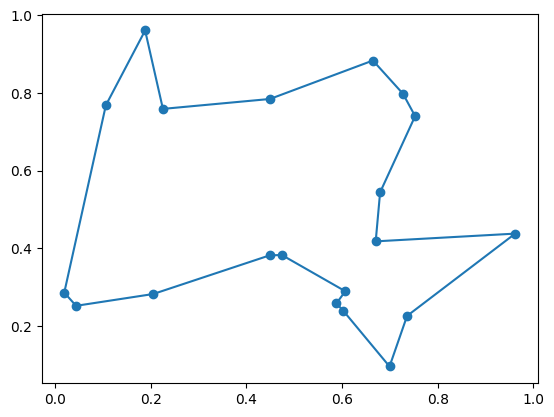

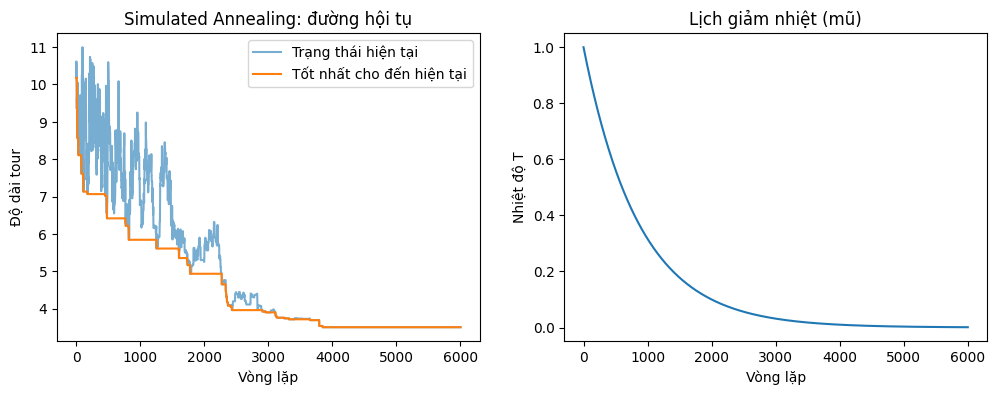

In [11]:
def simulated_annealing(tsp, tour = None, T0 = 1.0, alpha = 0.999, T_min = 1e-3, max_iter = 100000):
    """
    Simulated Annealing cho TSP.
    Mỗi vòng lặp: sinh một láng giềng ngẫu nhiên (hoán đổi hai thành phố), delta = độ dài mới - độ dài hiện tại.
      - delta < 0 : luôn chấp nhận (tốt hơn)
      - delta >= 0: chấp nhận với xác suất p = exp(-delta / T)  (có thể chấp nhận bước xấu để thoát local optimum)
    Lịch giảm nhiệt (mũ): T(t) = T0 * alpha^t. Dừng khi T <= T_min hoặc đạt max_iter.
    Trả về tour tốt nhất đã gặp trong quá trình chạy.
    """
    t0 = time.time()
    n = len(tsp["dist"])
    current = list(tour) if tour is not None else random_tour(n)
    current_len = tour_length(tsp, current)
    init_len = current_len

    best, best_len = current.copy(), current_len

    evaluations = 1
    iterations = 0
    accepted = 0
    accepted_worse = 0
    T = T0
    history = [best_len]              # độ dài tốt nhất cho đến hiện tại
    current_history = [current_len]   # độ dài của trạng thái hiện tại
    temperatures = [T]

    while T > T_min and iterations < max_iter:
        i, j = random.sample(range(n), 2)
        neighbor = current.copy()
        neighbor[i], neighbor[j] = neighbor[j], neighbor[i]
        neighbor_len = tour_length(tsp, neighbor)
        evaluations += 1

        delta = neighbor_len - current_len
        if delta < 0 or random.random() < math.exp(-delta / T):
            if delta >= 0:
                accepted_worse += 1
            current, current_len = neighbor, neighbor_len
            accepted += 1
            if current_len < best_len:
                best, best_len = current.copy(), current_len

        iterations += 1
        T = T0 * alpha ** iterations          # lịch giảm nhiệt dạng mũ
        history.append(best_len)
        current_history.append(current_len)
        temperatures.append(T)

    return {"tour": best, "length": best_len, "init_length": init_len,
            "iterations": iterations, "evaluations": evaluations,
            "accepted": accepted, "accepted_worse": accepted_worse,
            "time_ms": (time.time() - t0) * 1e3, "history": history,
            "current_history": current_history, "temperatures": temperatures}


# ---- Chạy thử trên bài toán dùng chung ----
# số vòng lặp mong muốn = 300 * n  ->  alpha = (T_min / T0) ** (1 / số vòng lặp)
sa_T0, sa_Tmin = 1.0, 1e-3
sa_alpha_demo = (sa_Tmin / sa_T0) ** (1 / (300 * n_demo))

random.seed(1)
res_sa = simulated_annealing(tsp_demo, start_tour, T0 = sa_T0, alpha = sa_alpha_demo, T_min = sa_Tmin)

print("=== Simulated Annealing (lịch mũ T(t) = T0 * alpha^t) ===")
print(f"T0 = {sa_T0}, alpha = {sa_alpha_demo:.6f}, T_min = {sa_Tmin}")
print(f"Độ dài tour ban đầu : {res_sa['init_length']:.4f}")
print(f"Độ dài tour tốt nhất: {res_sa['length']:.4f}")
print(f"Cải thiện tương đối : {(res_sa['init_length'] - res_sa['length']) / res_sa['init_length'] * 100:.2f} %")
print(f"Số vòng lặp         : {res_sa['iterations']}")
print(f"Số lần gọi tour_length(): {res_sa['evaluations']}")
print(f"Số bước được chấp nhận  : {res_sa['accepted']} (trong đó bước xấu hơn: {res_sa['accepted_worse']})")
print(f"Thời gian chạy      : {res_sa['time_ms']:.2f} ms")
print(f"Tour tốt nhất       : {res_sa['tour']}")
show_tsp(tsp_demo, res_sa["tour"])

fig, axes = plt.subplots(1, 2, figsize = (12, 4))
axes[0].plot(res_sa["current_history"], label = "Trạng thái hiện tại", alpha = 0.6)
axes[0].plot(res_sa["history"], label = "Tốt nhất cho đến hiện tại")
axes[0].set_xlabel("Vòng lặp")
axes[0].set_ylabel("Độ dài tour")
axes[0].set_title("Simulated Annealing: đường hội tụ")
axes[0].legend()
axes[1].plot(res_sa["temperatures"])
axes[1].set_xlabel("Vòng lặp")
axes[1].set_ylabel("Nhiệt độ T")
axes[1].set_title("Lịch giảm nhiệt (mũ)")
plt.show()

## Compare Performance [2 Points]

Use runtime, scalability (number of cities), and best objective function value to compare the algorithms on boards of different sizes.  

For timing you can use the `time` package.

In [12]:
import time

t0 = time.time()
print("Do something")
t1 = time.time()

print(f"This took: {(t1-t0) * 1e3} milliseconds")

Do something
This took: 0.0035762786865234375 milliseconds


Số thành phố khảo sát : [10, 20, 30, 40, 50]
Số lần chạy lặp lại   : 5 (seed 0..4); mọi thuật toán trong cùng một lần chạy dùng CÙNG tour khởi đầu
Random Restarts       : 10 lần khởi động
Simulated Annealing   : T0 = 1.0, T_min = 0.001, lịch mũ, số vòng lặp = 300 * n
Toán tử lân cận       : hoán đổi hai thành phố (dùng chung cho mọi thuật toán)
Hoàn thành n = 10
Hoàn thành n = 20
Hoàn thành n = 30
Hoàn thành n = 40
Hoàn thành n = 50

--- Độ dài tour cuối (f) của từng lần chạy ---
Thuật toán          Steepest-ascent  Random Restarts  Stochastic HC  First-choice HC  Simulated Annealing
n  Lần chạy (seed)                                                                                       
10 0                           2.33             2.33           2.82             2.33                 2.33
   1                           2.33             2.33           2.33             2.33                 2.33
   2                           2.33             2.33           2.33             2.33       

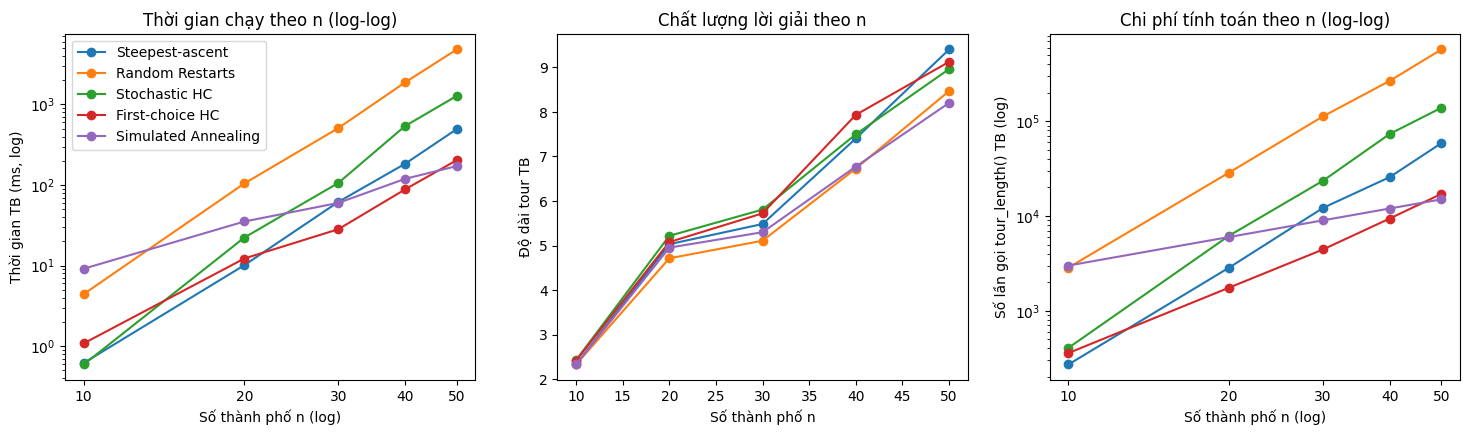

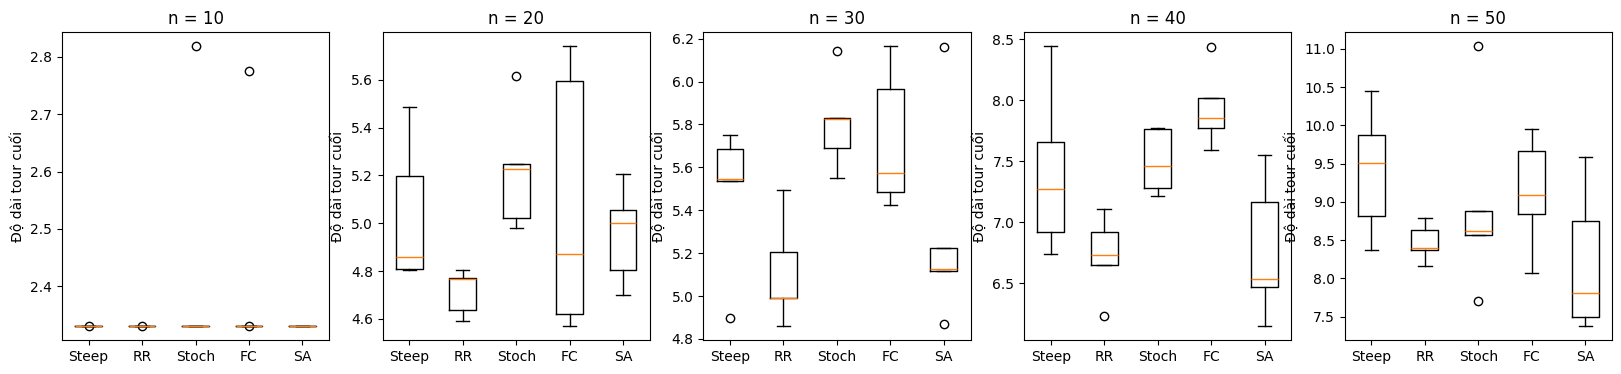


===== TOUR TRƯỚC KHI TỐI ƯU (n = 30, seed 0) =====
Tour length: 14.12


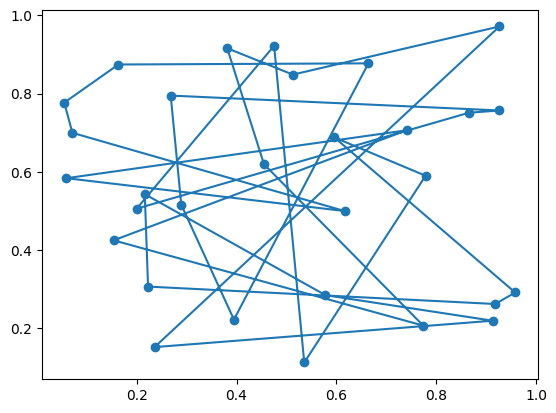


===== SAU KHI TỐI ƯU bằng Steepest-ascent (n = 30, seed 0) =====
Tour length: 5.54


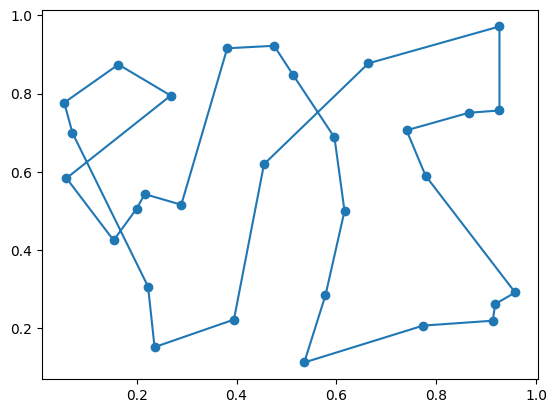


===== SAU KHI TỐI ƯU bằng Random Restarts (n = 30, seed 0) =====
Tour length: 5.49


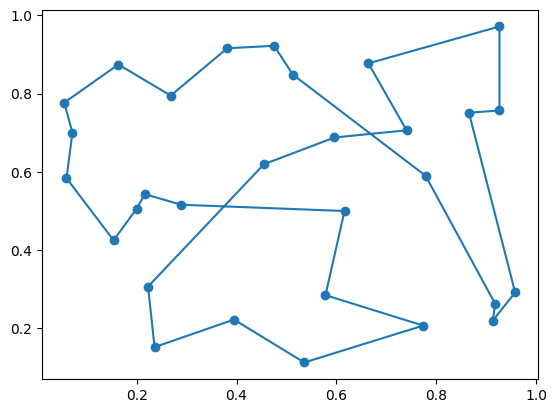


===== SAU KHI TỐI ƯU bằng Stochastic HC (n = 30, seed 0) =====
Tour length: 5.83


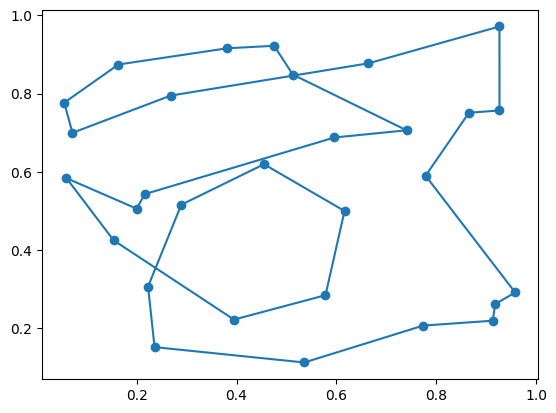


===== SAU KHI TỐI ƯU bằng First-choice HC (n = 30, seed 0) =====
Tour length: 5.43


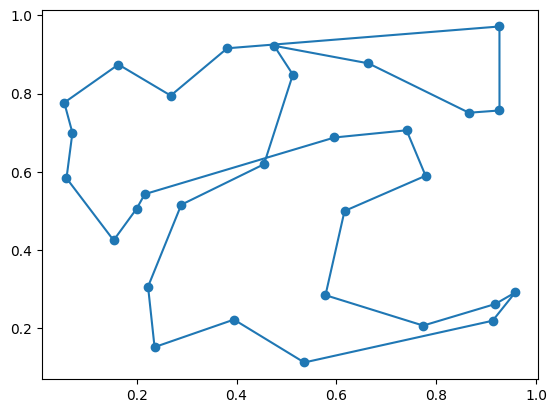


===== SAU KHI TỐI ƯU bằng Simulated Annealing (n = 30, seed 0) =====
Tour length: 5.22


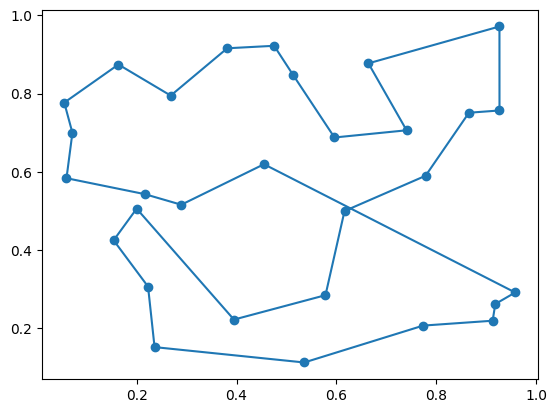

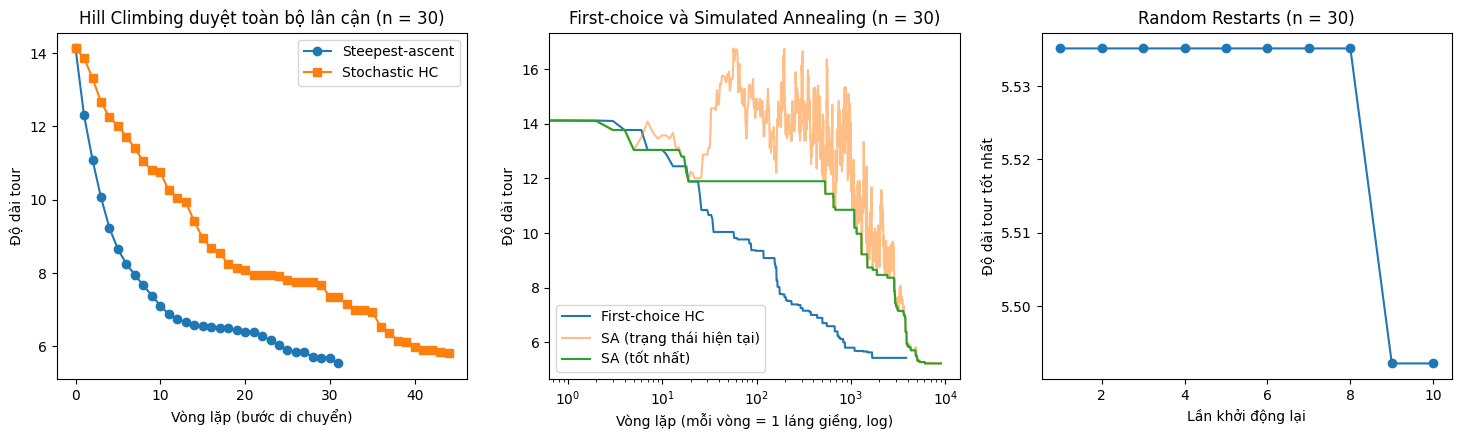

In [13]:
# ============================== THIẾT LẬP THÍ NGHIỆM ==============================
sizes = [10, 20, 30, 40, 50]      # số thành phố
n_runs = 5                        # số lần chạy lặp lại (seed 0 .. n_runs-1) cho mỗi (n, thuật toán)
n_restarts = 10                   # số lần restart của Random Restarts
sa_T0, sa_Tmin = 1.0, 1e-3        # SA: nhiệt độ đầu / cuối; số vòng lặp SA = 300 * n
algorithms = ["Steepest-ascent", "Random Restarts", "Stochastic HC", "First-choice HC", "Simulated Annealing"]

print(f"Số thành phố khảo sát : {sizes}")
print(f"Số lần chạy lặp lại   : {n_runs} (seed 0..{n_runs - 1}); mọi thuật toán trong cùng một lần chạy dùng CÙNG tour khởi đầu")
print(f"Random Restarts       : {n_restarts} lần khởi động")
print(f"Simulated Annealing   : T0 = {sa_T0}, T_min = {sa_Tmin}, lịch mũ, số vòng lặp = 300 * n")
print(f"Toán tử lân cận       : hoán đổi hai thành phố (dùng chung cho mọi thuật toán)")

# ============================== CHẠY THÍ NGHIỆM ==============================
records = []
instances = {}        # bài toán TSP cho mỗi n
run0_start = {}       # tour khởi đầu của lần chạy 0 (để vẽ trước/sau tối ưu)
run0_result = {}      # kết quả của lần chạy 0 (để vẽ tour và đường hội tụ)

for n in sizes:
    np.random.seed(1000 + n)
    tsp_n = random_tsp(n)
    instances[n] = tsp_n

    sa_iters = 300 * n
    sa_alpha = (sa_Tmin / sa_T0) ** (1 / sa_iters)

    for run in range(n_runs):
        random.seed(run)
        start = random_tour(n)
        init_len = tour_length(tsp_n, start)
        if run == 0:
            run0_start[n] = start

        for name in algorithms:
            random.seed(run)
            if name == "Steepest-ascent":
                res = steepest_ascent(tsp_n, start)
            elif name == "Random Restarts":
                res = steepest_ascent_random_restarts(tsp_n, n_restarts = n_restarts, tour = start)
            elif name == "Stochastic HC":
                res = stochastic_hill_climbing(tsp_n, start)
            elif name == "First-choice HC":
                res = first_choice_hill_climbing(tsp_n, start)
            else:
                res = simulated_annealing(tsp_n, start, T0 = sa_T0, alpha = sa_alpha, T_min = sa_Tmin)

            if run == 0:
                run0_result[(n, name)] = res

            records.append({"n": n, "Thuật toán": name, "Lần chạy (seed)": run,
                            "f ban đầu": init_len, "f cuối": res["length"],
                            "Cải thiện (%)": (init_len - res["length"]) / init_len * 100,
                            "Vòng lặp": res["iterations"], "Số lần đánh giá": res["evaluations"],
                            "Thời gian (ms)": res["time_ms"]})
    print(f"Hoàn thành n = {n}")

results = pd.DataFrame(records)

# ============================== BẢNG KẾT QUẢ CHI TIẾT TỪNG LẦN CHẠY ==============================
print("\n--- Độ dài tour cuối (f) của từng lần chạy ---")
display_runs = results.pivot_table(index = ["n", "Lần chạy (seed)"], columns = "Thuật toán", values = "f cuối")[algorithms]
print(display_runs.to_string())

# ============================== BẢNG TỔNG HỢP ==============================
summary = results.groupby(["n", "Thuật toán"], sort = False).agg(
    **{"f tốt nhất (min)": ("f cuối", "min"),
       "f trung bình": ("f cuối", "mean"),
       "f tệ nhất (max)": ("f cuối", "max"),
       "Độ lệch chuẩn f": ("f cuối", "std"),
       "f ban đầu TB": ("f ban đầu", "mean"),
       "Cải thiện TB (%)": ("Cải thiện (%)", "mean"),
       "Vòng lặp TB": ("Vòng lặp", "mean"),
       "Số lần đánh giá TB": ("Số lần đánh giá", "mean"),
       "Thời gian TB (ms)": ("Thời gian (ms)", "mean"),
       "Thời gian min (ms)": ("Thời gian (ms)", "min"),
       "Thời gian max (ms)": ("Thời gian (ms)", "max")}
).reset_index()
# ============================== BẢNG THEO TỪNG n (để dễ đối chiếu) ==============================
for n in sizes:
    print(f"\n===== n = {n} thành phố  (số láng giềng = {n * (n - 1) // 2}) =====")
    print(summary[summary["n"] == n].drop(columns = "n").round(3).to_string(index = False))

# ============================== ĐỒ THỊ: THỜI GIAN & CHẤT LƯỢNG THEO n ==============================
fig, axes = plt.subplots(1, 3, figsize = (18, 4.5))
for name in algorithms:
    sub = summary[summary["Thuật toán"] == name]
    axes[0].plot(sub["n"], sub["Thời gian TB (ms)"], marker = "o", label = name)
    axes[1].plot(sub["n"], sub["f trung bình"], marker = "o", label = name)
    axes[2].plot(sub["n"], sub["Số lần đánh giá TB"], marker = "o", label = name)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xticks(sizes); axes[0].set_xticklabels(sizes)
axes[0].set_xlabel("Số thành phố n (log)"); axes[0].set_ylabel("Thời gian TB (ms, log)")
axes[0].set_title("Thời gian chạy theo n (log-log)"); axes[0].legend()
axes[1].set_xlabel("Số thành phố n"); axes[1].set_ylabel("Độ dài tour TB")
axes[1].set_title("Chất lượng lời giải theo n")
axes[2].set_xscale("log"); axes[2].set_yscale("log")
axes[2].set_xticks(sizes); axes[2].set_xticklabels(sizes)
axes[2].set_xlabel("Số thành phố n (log)"); axes[2].set_ylabel("Số lần gọi tour_length() TB (log)")
axes[2].set_title("Chi phí tính toán theo n (log-log)")
plt.show()

# ============================== ĐỒ THỊ: HỘP (BOX) ĐỘ DÀI TOUR THEO THUẬT TOÁN ==============================
fig, axes = plt.subplots(1, len(sizes), figsize = (4 * len(sizes), 4))
for k, n in enumerate(sizes):
    data = [results[(results["n"] == n) & (results["Thuật toán"] == name)]["f cuối"].values for name in algorithms]
    axes[k].boxplot(data)
    axes[k].set_xticklabels(["Steep", "RR", "Stoch", "FC", "SA"])
    axes[k].set_title(f"n = {n}")
    axes[k].set_ylabel("Độ dài tour cuối")
plt.show()

# ============================== TOUR TRƯỚC / SAU TỐI ƯU (n = 30, lần chạy seed 0) ==============================
n_show = 30
print(f"\n===== TOUR TRƯỚC KHI TỐI ƯU (n = {n_show}, seed 0) =====")
show_tsp(instances[n_show], run0_start[n_show])
for name in algorithms:
    print(f"\n===== SAU KHI TỐI ƯU bằng {name} (n = {n_show}, seed 0) =====")
    show_tsp(instances[n_show], run0_result[(n_show, name)]["tour"])

# ============================== ĐƯỜNG HỘI TỤ (n = 30, lần chạy seed 0) ==============================
fig, axes = plt.subplots(1, 3, figsize = (18, 4.5))
axes[0].plot(run0_result[(n_show, "Steepest-ascent")]["history"], marker = "o", label = "Steepest-ascent")
axes[0].plot(run0_result[(n_show, "Stochastic HC")]["history"], marker = "s", label = "Stochastic HC")
axes[0].set_xlabel("Vòng lặp (bước di chuyển)"); axes[0].set_ylabel("Độ dài tour")
axes[0].set_title(f"Hill Climbing duyệt toàn bộ lân cận (n = {n_show})"); axes[0].legend()
axes[1].plot(run0_result[(n_show, "First-choice HC")]["history"], label = "First-choice HC")
axes[1].plot(run0_result[(n_show, "Simulated Annealing")]["current_history"], label = "SA (trạng thái hiện tại)", alpha = 0.5)
axes[1].plot(run0_result[(n_show, "Simulated Annealing")]["history"], label = "SA (tốt nhất)")
axes[1].set_xscale("log")
axes[1].set_xlabel("Vòng lặp (mỗi vòng = 1 láng giềng, log)"); axes[1].set_ylabel("Độ dài tour")
axes[1].set_title(f"First-choice và Simulated Annealing (n = {n_show})"); axes[1].legend()
axes[2].plot(range(1, n_restarts + 1), run0_result[(n_show, "Random Restarts")]["history"], marker = "o")
axes[2].set_xlabel("Lần khởi động lại"); axes[2].set_ylabel("Độ dài tour tốt nhất")
axes[2].set_title(f"Random Restarts (n = {n_show})")
plt.show()

### Nhận xét kết quả so sánh (từ các output ở trên)

* **Cực trị cục bộ:** mọi biến thể Hill Climbing đều dừng ở local optimum nên chất lượng phụ thuộc mạnh vào tour khởi đầu (độ lệch chuẩn của `f` lớn, nhất là khi n tăng). Ở n = 10, Steepest-ascent, Random Restarts và SA đều cho cùng tour 2.33 ở cả 5 lần chạy, trong khi Stochastic và First-choice vẫn có lần kẹt ở tour dài hơn.
* **Random Restarts:** cho `f` trung bình tốt hơn và ổn định hơn (độ lệch chuẩn thấp hơn) so với một lần Steepest-ascent ở mọi n ≥ 20, nhưng phải trả giá gần gấp 10 lần số lần đánh giá và thời gian (do 10 lần restart).
* **Simulated Annealing:** nhờ chấp nhận có điều kiện các bước xấu hơn nên thoát được nhiều local optimum; ở n lớn (40, 50) SA có `f` trung bình thấp nhất hoặc gần thấp nhất, mà số lần đánh giá chỉ bằng một phần nhỏ so với Random Restarts. Tuy vậy, với ngân sách cố định 300·n vòng lặp, kết quả giữa các seed vẫn dao động (có lần chạy kém hơn hẳn).
* **First-choice vs Stochastic vs Steepest:** khi n ≥ 20, First-choice dùng ít lần đánh giá nhất trong ba biến thể Hill Climbing một lần chạy nhưng chất lượng không ổn định; Stochastic và Steepest phải duyệt toàn bộ $n(n-1)/2$ láng giềng ở mỗi bước nên chi phí tăng rất nhanh theo n.
* **Khả năng mở rộng (log-log):** thời gian của Steepest-ascent, Stochastic và Random Restarts tăng xấp xỉ theo luỹ thừa 4 của n (số bước ∝ n, số láng giềng ∝ n², mỗi lần `tour_length()` tốn O(n)); First-choice thấp hơn, còn SA tăng chậm nhất (xấp xỉ luỹ thừa 1–2 của n) vì mỗi vòng lặp chỉ đánh giá một láng giềng. Giá trị thời gian cụ thể phụ thuộc máy chạy.
* **Hạn chế:** toán tử hoán đổi hai thành phố là toán tử "thô" (một phép hoán đổi thay tới 4 cạnh của tour và khó gỡ các cạnh giao nhau); toán tử 2-opt thường cho tour tốt hơn. Các thuật toán đều là heuristic, không đảm bảo tối ưu toàn cục, và SA nhạy với T0, alpha và số vòng lặp.

## Bonus: Genetic Algorithm [+1 Point]

=== Genetic Algorithm ===
Độ dài trung bình quần thể ban đầu: 9.7900
Độ dài tour tốt nhất : 3.9979
Số thế hệ            : 300
Số lần gọi tour_length(): 30100
Thời gian chạy       : 594.27 ms
Tour tốt nhất        : [17, 5, 2, 16, 14, 6, 11, 13, 19, 1, 12, 0, 15, 4, 3, 10, 9, 8, 18, 7]
Tour length: 4.0


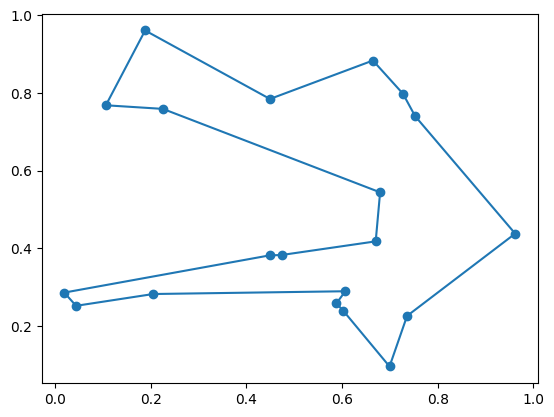

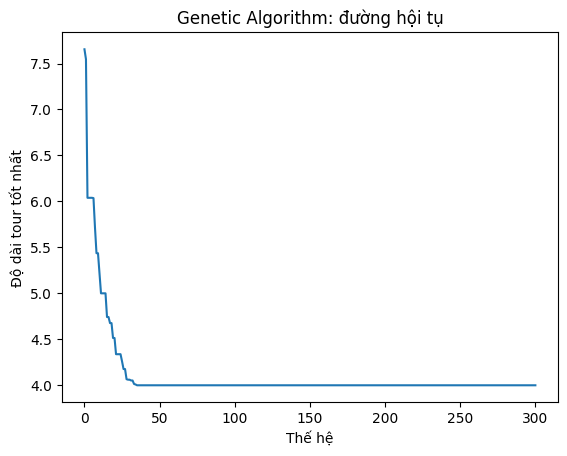


So sánh trên bài toán dùng chung (n = 20), độ dài tour ban đầu = 10.1787


,Thuật toán,f cuối,Số lần đánh giá,Thời gian (ms)
0,Steepest-ascent,4.17,2471,9.47
1,Random Restarts,3.62,58160,174.73
2,Stochastic HC,4.07,7601,31.57
3,First-choice HC,4.07,2194,8.46
4,Simulated Annealing,3.50,6002,27.53
5,Genetic Algorithm,4.00,30100,594.27


In [14]:
def genetic_algorithm(tsp, pop_size = 100, generations = 300, mutation_rate = 0.2, n_elite = 2, tournament_size = 3):
    """
    Genetic Algorithm cho TSP (bonus).
      - Cá thể: một hoán vị các thành phố (tour).
      - Chọn lọc: tournament selection.
      - Lai ghép: Order Crossover (OX) - giữ một đoạn của cha, phần còn lại điền theo thứ tự của mẹ.
      - Đột biến: hoán đổi hai thành phố (cùng toán tử lân cận như các thuật toán trên).
      - Elitism: giữ lại n_elite cá thể tốt nhất sang thế hệ sau.
    """
    t0 = time.time()
    n = len(tsp["dist"])

    population = [random_tour(n) for _ in range(pop_size)]
    fitness = [tour_length(tsp, ind) for ind in population]
    evaluations = pop_size

    init_len = float(np.mean(fitness))      # độ dài trung bình của quần thể ban đầu
    best_idx = int(np.argmin(fitness))
    best, best_len = population[best_idx].copy(), fitness[best_idx]
    history = [best_len]

    for g in range(generations):
        order = np.argsort(fitness)
        new_population = [population[k].copy() for k in order[:n_elite]]

        while len(new_population) < pop_size:
            # tournament selection cho cha và mẹ
            cand = random.sample(range(pop_size), tournament_size)
            p1 = population[cand[int(np.argmin([fitness[c] for c in cand]))]]
            cand = random.sample(range(pop_size), tournament_size)
            p2 = population[cand[int(np.argmin([fitness[c] for c in cand]))]]

            # Order Crossover (OX)
            a, b = sorted(random.sample(range(n), 2))
            segment = p1[a:b + 1]
            in_segment = set(segment)
            rest = [c for c in p2 if c not in in_segment]
            child = rest[:a] + segment + rest[a:]

            # đột biến: hoán đổi hai thành phố
            if random.random() < mutation_rate:
                i, j = random.sample(range(n), 2)
                child[i], child[j] = child[j], child[i]

            new_population.append(child)

        population = new_population
        fitness = [tour_length(tsp, ind) for ind in population]
        evaluations += pop_size

        best_idx = int(np.argmin(fitness))
        if fitness[best_idx] < best_len:
            best, best_len = population[best_idx].copy(), fitness[best_idx]
        history.append(best_len)

    return {"tour": best, "length": best_len, "init_length": init_len,
            "iterations": generations, "evaluations": evaluations,
            "time_ms": (time.time() - t0) * 1e3, "history": history}


# ---- Chạy thử trên bài toán dùng chung (20 thành phố) ----
random.seed(1)
res_ga = genetic_algorithm(tsp_demo, pop_size = 100, generations = 300, mutation_rate = 0.2)

print("=== Genetic Algorithm ===")
print(f"Độ dài trung bình quần thể ban đầu: {res_ga['init_length']:.4f}")
print(f"Độ dài tour tốt nhất : {res_ga['length']:.4f}")
print(f"Số thế hệ            : {res_ga['iterations']}")
print(f"Số lần gọi tour_length(): {res_ga['evaluations']}")
print(f"Thời gian chạy       : {res_ga['time_ms']:.2f} ms")
print(f"Tour tốt nhất        : {res_ga['tour']}")
show_tsp(tsp_demo, res_ga["tour"])

plt.plot(res_ga["history"])
plt.xlabel("Thế hệ")
plt.ylabel("Độ dài tour tốt nhất")
plt.title("Genetic Algorithm: đường hội tụ")
plt.show()

# ---- So sánh GA với các thuật toán khác trên cùng bài toán dùng chung ----
comparison = pd.DataFrame([
    {"Thuật toán": "Steepest-ascent", "f cuối": res_steepest["length"], "Số lần đánh giá": res_steepest["evaluations"], "Thời gian (ms)": res_steepest["time_ms"]},
    {"Thuật toán": "Random Restarts", "f cuối": res_rr["length"], "Số lần đánh giá": res_rr["evaluations"], "Thời gian (ms)": res_rr["time_ms"]},
    {"Thuật toán": "Stochastic HC", "f cuối": res_stoch["length"], "Số lần đánh giá": res_stoch["evaluations"], "Thời gian (ms)": res_stoch["time_ms"]},
    {"Thuật toán": "First-choice HC", "f cuối": res_fc["length"], "Số lần đánh giá": res_fc["evaluations"], "Thời gian (ms)": res_fc["time_ms"]},
    {"Thuật toán": "Simulated Annealing", "f cuối": res_sa["length"], "Số lần đánh giá": res_sa["evaluations"], "Thời gian (ms)": res_sa["time_ms"]},
    {"Thuật toán": "Genetic Algorithm", "f cuối": res_ga["length"], "Số lần đánh giá": res_ga["evaluations"], "Thời gian (ms)": res_ga["time_ms"]},
])
print(f"\nSo sánh trên bài toán dùng chung (n = {n_demo}), độ dài tour ban đầu = {tour_length(tsp_demo, start_tour):.4f}")
comparison